# Embedding the crops

Every crop goes once through each frozen backbone, and its vector is stored.

| Cache | Backbone | Used by |
|---|---|---|
| `dinov3_vitl16_cls` | DINOv3 ViT-L/16 class token, 1024-d | species and sex probes, step 3 of re-ID |
| `bioclip2.5_vith14` | BioCLIP 2.5 ViT-H/14, 1024-d | the backbone comparison |
| `miewid_msv3` | MiewID-msv3 zero-shot, 2152-d | step 1 of re-ID |
| `miewid_msv3_finetuned_<run>` | MiewID after `2_finetune_miewid.ipynb` | steps 2-7 of re-ID |
| `miewid_msv3_finetuned_<run>_raw` | the same, before the L2 normalisation | the PFE benchmark |

`<run>` is the folder of the checkpoint, so a new training run writes a new cache. Every backbone reads the
2048 px JPEG copies in `data_root/segmented_compressed/`. A cache is keyed by crop name. DINOv3 needs its weights in `<cache_dir>/models/`.

## Settings

In [18]:
import tomllib
from pathlib import Path

ROOT = Path.cwd().parent
CONFIG = tomllib.loads((ROOT / "config.toml").read_text())

# Relative paths in config.toml start at the folder that holds it.
DATA_ROOT = ROOT / Path(CONFIG["data_root"]).expanduser()
SEGMENTED_COMPRESSED = DATA_ROOT / "segmented_compressed"
CHECKPOINT = ROOT / Path(CONFIG["miewid_checkpoint"]).expanduser()
assert SEGMENTED_COMPRESSED.exists(), f"Not found: {SEGMENTED_COMPRESSED}. Check the paths in {ROOT / 'config.toml'}."
assert CHECKPOINT.exists(), f"No checkpoint at {CHECKPOINT}. Run 2_finetune_miewid.ipynb first."

## The SAM 3 score of each crop

SAM 3 can find several seahorses in one photograph, so a photograph can have several crops.  

In [19]:
import json

crop_scores = {}

# Reuse older pipeline (when notebook 1 did not run)
summary = DATA_ROOT / "summary.json"
if summary.exists():
    for record in json.loads(summary.read_text())["results"]:
        stem = Path(record["image_key"]).stem
        for index, score in enumerate(record.get("scores") or []):
            crop_scores[f"{stem}_det{index}_cropped.jpg"] = score
    print(f"summary.json: {len(crop_scores)} crops")

# Use the notebook 1 results (detections.json)
detections = DATA_ROOT / "detections.json"
if detections.exists():
    recorded = {record["name"]: record["score"] for record in json.loads(detections.read_text())}
    crop_scores.update(recorded)
    print(f"detections.json: {len(recorded)} crops")
print(f"{len(crop_scores)} crops have a SAM 3 score")

summary.json: 30979 crops
30979 crops have a SAM 3 score


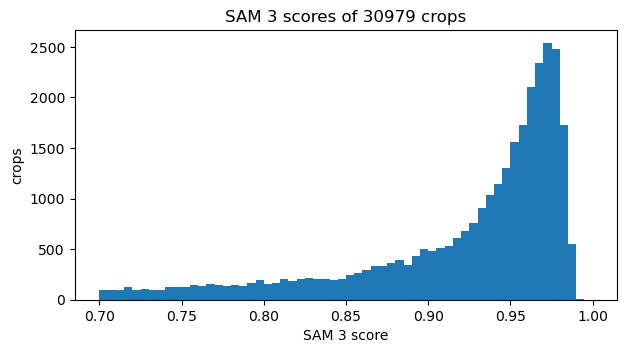

In [20]:
import matplotlib.pyplot as plt

# SAM 3 keeps only the detections at or above 0.7 (BOX_THRESHOLD in 1_segment_images.ipynb), so the
# scores start at 0.7.
scores = list(crop_scores.values())
figure, axis = plt.subplots(figsize=(7, 3.5))
axis.hist(scores, bins=60, range=(0.7, 1.0), color="tab:blue")
axis.set_xlabel("SAM 3 score")
axis.set_ylabel("crops")
axis.set_title(f"SAM 3 scores of {len(scores)} crops")
plt.show()

## One crop per photograph

Each photograph keeps the SAM 3 detection with the highest score. SAM 3 lists its detections in
the order of its internal queries, not by score, so `_det0` is not always the best crop. Ties go
to the lower detection number. 

In [21]:
import re

import pandas as pd
from itables import init_notebook_mode, show

init_notebook_mode(all_interactive=True)  # every DataFrame shown from here on is interactive

CROP = re.compile(r"^(?P<photograph>.+)_det(?P<number>\d+)_cropped\.jpg$")

crop_files = pd.Series(sorted(path.name for path in SEGMENTED_COMPRESSED.glob("*.jpg")))
# "detection number" is the N of _detN: SAM 3 numbers the crops of a photograph from 0.
detected = (crop_files.str.extract(CROP).rename(columns={"number": "detection number"})
            .assign(name=crop_files))
detected["detection number"] = pd.to_numeric(detected["detection number"]).astype("Int64")  # integers, missing allowed
detected["score"] = detected["name"].map(crop_scores)
several = detected.groupby("photograph")["name"].transform("size") > 1
assert detected.loc[several, "score"].notna().all(), "A photograph with several crops has no SAM 3 score"
best = (detected.dropna(subset=["photograph"])
        .sort_values(["photograph", "score", "detection number"], ascending=[True, False, True])
        .drop_duplicates("photograph"))
# Kept: the best crop of each photograph, and every file that is not a SAM 3 crop.
detected["kept"] = detected.index.isin(best.index) | detected["photograph"].isna()
best_crops = detected.loc[detected["kept"], "name"].tolist()  # sorted by name, as crop_files
print(f"{len(crop_files)} crops of {detected['photograph'].nunique()} photographs; "
      f"{several.sum()} crops come from photographs with several; {len(best_crops)} kept")
show(detected, scrollY="400px", scroller=True, maxBytes=0, showIndex=False)

30932 crops of 30500 photographs; 834 crops come from photographs with several; 30500 kept


The crops of the first photograph with several detections. The kept crop has the highest score.

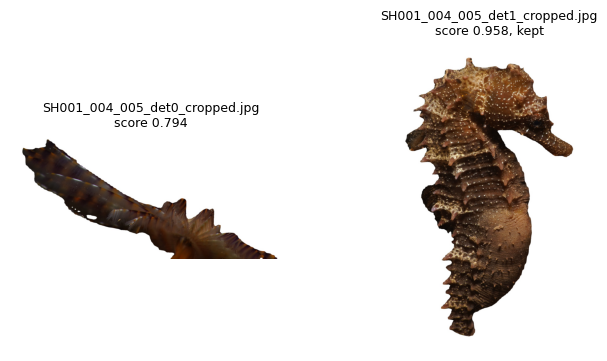

In [22]:
from PIL import Image

example_crops = detected[detected["photograph"] == detected.loc[several, "photograph"].iloc[0]]
figure, axes = plt.subplots(1, len(example_crops), figsize=(4 * len(example_crops), 4))
for axis, crop in zip(axes, example_crops.itertuples()):
    axis.imshow(Image.open(SEGMENTED_COMPRESSED / crop.name))
    axis.set_title(f"{crop.name}\nscore {crop.score:.3f}" + (", kept" if crop.kept else ""), fontsize=9)
    axis.axis("off")
plt.show()

## The crops to embed

Crops whose name does not follow `SH<identity>_<observation>_<photo>` are left out.

In [23]:
# 'SH024_002_007_det0_cropped.jpg' -> individual 'SH024', observation number '002'. The photo number
# and SAM 3's suffixes (_det<n>, _segmented, _mask, _cropped, _annotated) are optional.
PHOTO_NAME = re.compile(r"^(?P<identity>SH\d+)_(?P<number>\d+)(?:_\d+)?"
                        r"(?:_det\d+|_segmented|_mask|_cropped|_annotated)*(?:\.[^.]+)?$")

names = [name for name in best_crops if PHOTO_NAME.match(name) is not None]
print(f"{len(names)} crops to embed; left out: {sorted(set(best_crops) - set(names))}")

30500 crops to embed; left out: []


## The input of each backbone

Every backbone reads the 2048 px JPEG copy of a crop and brings it to a square input the same way.
The crop is centred on a white square, so no view is stretched, and the square is resized with
Lanczos. The pixels are then rescaled to 0-1 and normalised with the colour statistics of the
backbone's training images. Only the side and these statistics differ between backbones: 440 px
for MiewID, 224 px for DINOv3 and BioCLIP. At these sizes, the JPEG copy holds all the detail
that the full-resolution PNG holds.

The panels show the example crop and its two input sizes, with the normalisation undone so the
input is visible. The frame marks the edge of each image.

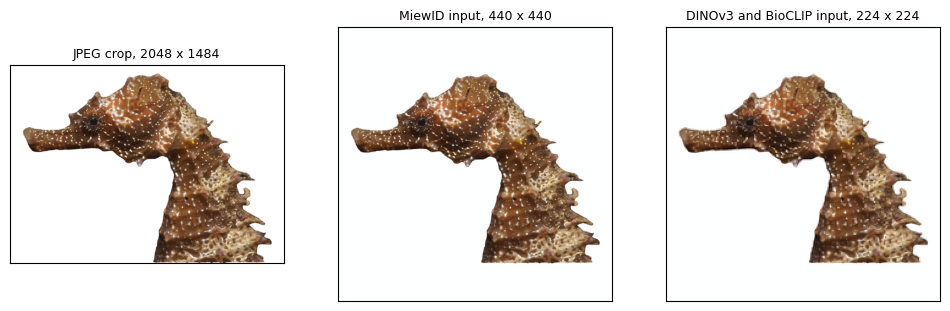

In [24]:
import numpy as np
import torch
from PIL import ImageOps
from torchvision import transforms

EXAMPLE = "SH001_002_007_det0_cropped.jpg"
IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
CLIP_MEAN, CLIP_STD = (0.48145466, 0.4578275, 0.40821073), (0.26862954, 0.26130258, 0.27577711)
# The input of each backbone: its side in pixels, and the colour statistics of its training images.
INPUT_SETTINGS = {"miewid": (440, IMAGENET_MEAN, IMAGENET_STD), "dinov3": (224, IMAGENET_MEAN, IMAGENET_STD),
                  "bioclip": (224, CLIP_MEAN, CLIP_STD)}
# Centre the crop on a white square, so no view is stretched; white matches the background that the
# segmentation paints, exactly (255, 255, 255). Then resize with Lanczos, rescale to 0-1 with colour
# first, and normalise.
INPUT = {backbone: transforms.Compose([
             transforms.Lambda(lambda image: ImageOps.pad(image, (max(image.size),) * 2, color=(255, 255, 255))),
             transforms.Resize((size, size), interpolation=transforms.InterpolationMode.LANCZOS),
             transforms.ToTensor(),
             transforms.Normalize(mean=mean, std=std)])
         for backbone, (size, mean, std) in INPUT_SETTINGS.items()}

crop = Image.open(SEGMENTED_COMPRESSED / EXAMPLE).convert("RGB")
panels = [(np.asarray(crop) / 255, f"JPEG crop, {crop.width} x {crop.height}")]
for backbone, label in [("miewid", "MiewID"), ("dinov3", "DINOv3 and BioCLIP")]:
    size, mean, std = INPUT_SETTINGS[backbone]
    pixels = INPUT[backbone](crop).numpy().transpose(1, 2, 0) * std + mean
    panels.append((pixels, f"{label} input, {size} x {size}"))
figure, axes = plt.subplots(1, len(panels), figsize=(12, 4))
for axis, (pixels, title) in zip(axes, panels):
    axis.imshow(np.clip(pixels, 0, 1))
    axis.set_title(title, fontsize=9)
    axis.set_xticks([])
    axis.set_yticks([])  # the frame shows the edge of the input, white padding included
plt.show()

## What each cache lacks

Each cache gains only the embeddings of the crops it lacks.

Each cache records the preprocessing that made it. A cache made another way stops the notebook, so old and new embeddings never mix in one cache. Move such caches
out of `<cache_dir>/embeddings/` before the run.

In [25]:
CACHE_DIR = ROOT / Path(CONFIG["cache_dir"]).expanduser()
EMBEDDINGS = CACHE_DIR / "embeddings"
# Written into every cache, and checked before a cache is reused.
PREPROCESSING = "2048 px JPEG, white square pad, Lanczos resize"
MIEWID_DIM = 2152  # length of a MiewID-msv3 embedding
FINETUNED = f"miewid_msv3_finetuned_{CHECKPOINT.parent.name}"  # the training run names the cache
CACHES = {"dinov3_vitl16_cls": 1024, "bioclip2.5_vith14": 1024, "miewid_msv3": MIEWID_DIM,
          FINETUNED: MIEWID_DIM, f"{FINETUNED}_raw": MIEWID_DIM}  # cache name -> vector length

missing_by_cache, rows = {}, []
for cache_name, dim in CACHES.items():
    stored = set()
    cache_path = EMBEDDINGS / f"{cache_name}.npz"
    if cache_path.exists():
        with np.load(cache_path) as cache:
            assert cache["dim"] == dim, f"{cache_path.name} holds vectors of another length"
            assert "preprocessing" in cache.files and cache["preprocessing"] == PREPROCESSING, (
                f"{cache_path} was made with another preprocessing. Move it out of {EMBEDDINGS}.")
            stored = set(cache["names"].tolist())
    missing_by_cache[cache_name] = [name for name in names if name not in stored]
    rows.append({"cache": cache_name, "vector length": dim, "stored": len(stored),
                 "missing": len(missing_by_cache[cache_name])})
display(pd.DataFrame(rows))
if any(missing_by_cache.values()):
    assert torch.cuda.is_available(), "Some caches lack embeddings: extracting them needs a GPU."

AssertionError: /home/tristan-fauvel/Documents/Baysic_Labs/Projet Hippocampes/animal-reID/searide-scripts/paper_notebooks/../paper_release/cache/embeddings/dinov3_vitl16_cls.npz was made with another preprocessing. Move it out of /home/tristan-fauvel/Documents/Baysic_Labs/Projet Hippocampes/animal-reID/searide-scripts/paper_notebooks/../paper_release/cache/embeddings.

## Extracting

One backbone at a time, so only one set of weights is on the GPU. `extract` sends the missing crops
through the model in batches, and writes the cache every 4096 images and at the end, even after an
error. A complete cache is skipped. `model.eval()` makes the same image always give the same
embedding.

### DINOv3

The class token summarises the whole image.

In [ ]:
import torch.nn as nn

DEVICE = "cuda"
BATCH = 16
FLUSH_EVERY = 4096  # images between two writes of a cache
DINOV3_WEIGHTS = "dinov3_vitl16_pretrain_lvd1689m-8aa4cbdd.pth"  # in <cache_dir>/models/


def write_embeddings(path, dim, vectors):
    """Write a cache {name: vector} through a temporary file, so a stopped write cannot corrupt it."""
    path.parent.mkdir(parents=True, exist_ok=True)
    names = list(vectors)
    temporary = path.with_name(path.name + ".tmp")
    with temporary.open("wb") as handle:  # through a handle, or numpy appends its own .npz
        np.savez_compressed(handle, dim=dim, preprocessing=PREPROCESSING, names=names,
                            embeddings=np.stack([vectors[name] for name in names]).astype(np.float32))
    temporary.replace(path)


def extract(cache_name, prepare, encode):
    """Add to a cache the embeddings of the crops it lacks.

    prepare turns a JPEG crop into an input tensor, and encode turns a batch of inputs into
    embeddings.
    """
    cache_path = EMBEDDINGS / f"{cache_name}.npz"
    missing = missing_by_cache[cache_name]
    if not missing:
        print(f"{cache_path.name}: complete")
        return
    vectors = {}
    if cache_path.exists():
        with np.load(cache_path) as stored:
            vectors = dict(zip(stored["names"].tolist(), stored["embeddings"]))
    print(f"{cache_path.name}: extracting {len(missing)} of {len(names)} images on {DEVICE}")
    done = 0
    try:
        with torch.no_grad():
            for start in range(0, len(missing), BATCH):
                batch_names = missing[start:start + BATCH]
                batch = torch.stack([prepare(Image.open(SEGMENTED_COMPRESSED / name).convert("RGB"))
                                     for name in batch_names])
                output = encode(batch.to(DEVICE)).cpu().numpy()  # float32
                assert np.isfinite(output).all(), "the model gave non-finite embeddings"
                vectors.update(zip(batch_names, output))
                done += len(batch_names)
                if done % FLUSH_EVERY < BATCH:
                    write_embeddings(cache_path, CACHES[cache_name], vectors)
                    print(f"  {done}/{len(missing)}")
    finally:
        write_embeddings(cache_path, CACHES[cache_name], vectors)  # keep what finished, even after an error
    print(f"{cache_path.name}: {len(missing)} embeddings written")


if missing_by_cache["dinov3_vitl16_cls"]:
    weights = CACHE_DIR / "models" / DINOV3_WEIGHTS
    assert weights.exists(), f"Download the DINOv3 weights from github.com/facebookresearch/dinov3 to {weights}"
    model = torch.hub.load("facebookresearch/dinov3", "dinov3_vitl16", weights=str(weights)).to(DEVICE).eval()
    extract("dinov3_vitl16_cls", INPUT["dinov3"],
            lambda batch: nn.functional.normalize(model.forward_features(batch)["x_norm_clstoken"].float(), dim=-1))
    model.to("cpu")  # free the GPU for the next backbone
else:
    print("dinov3_vitl16_cls.npz: complete")

### BioCLIP 2.5

BioCLIP reads images and text; only the image half is used. The paper's BioCLIP cache was made in
half precision on a GPU, so the weights and the batches are halved.

In [ ]:
import open_clip

BIOCLIP_MODEL = "hf-hub:imageomics/bioclip-2.5-vith14"

if missing_by_cache["bioclip2.5_vith14"]:
    model, _, _ = open_clip.create_model_and_transforms(BIOCLIP_MODEL)
    model.half().to(DEVICE).eval()
    extract("bioclip2.5_vith14", INPUT["bioclip"],
            lambda batch: nn.functional.normalize(model.encode_image(batch.half()).float(), dim=-1))
    model.to("cpu")
else:
    print("bioclip2.5_vith14.npz: complete")

### MiewID zero-shot

MiewID is published on Hugging Face as loose Python files, not as a library. `load_miewid`
registers the downloaded folder under a made-up package name, imports it and loads the public
weights.

In [ ]:
import importlib
import sys
import types

from huggingface_hub import snapshot_download
from safetensors.torch import load_file

MIEWID_MODEL = "conservationxlabs/miewid-msv3"


def load_miewid():
    """MiewID-msv3 with its public weights, on the CPU."""
    model_dir = Path(snapshot_download(MIEWID_MODEL))
    package_name = f"_miewid_{model_dir.name.replace('-', '_')}"
    if package_name not in sys.modules:
        package = types.ModuleType(package_name)
        package.__path__ = [str(model_dir)]
        sys.modules[package_name] = package
    modeling = importlib.import_module(f"{package_name}.modeling_miewid")
    configuration = importlib.import_module(f"{package_name}.configuration_miewid")
    config = configuration.MiewIdNetConfig.from_pretrained(MIEWID_MODEL)
    config.pretrained = False  # the next line loads the weights
    model = modeling.MiewIdNet(config)
    model.load_state_dict(load_file(str(model_dir / "model.safetensors")), strict=False)
    return model


if missing_by_cache["miewid_msv3"]:
    model = load_miewid().to(DEVICE).eval()
    extract("miewid_msv3", INPUT["miewid"],
            lambda batch: nn.functional.normalize(model(batch), p=2, dim=1))
    model.to("cpu")
else:
    print("miewid_msv3.npz: complete")

### MiewID fine-tuned

The checkpoint of `2_finetune_miewid.ipynb` replaces the public weights. One model fills two
caches: one with L2-normalised vectors, and a `_raw` one with the vectors before the
normalisation, for PFE.

In [ ]:
import pathlib

if missing_by_cache[FINETUNED] or missing_by_cache[f"{FINETUNED}_raw"]:
    model = load_miewid()
    # The released checkpoint stores a PosixPath. Allow that one class, rather than turning off
    # weights_only, which would allow arbitrary code.
    torch.serialization.add_safe_globals([pathlib.PosixPath, pathlib.WindowsPath])
    state = torch.load(CHECKPOINT, map_location="cpu", weights_only=True)["model_state_dict"]
    # An earlier training script wrapped the encoder and prefixed every weight name.
    prefix = "feature_extractor."
    if all(key.startswith(prefix) for key in state):
        state = {key.removeprefix(prefix): value for key, value in state.items()}
    model.load_state_dict(state, strict=True)  # strict: a skipped weight would stay untrained
    model.to(DEVICE).eval()
    extract(FINETUNED, INPUT["miewid"],
            lambda batch: nn.functional.normalize(model(batch), p=2, dim=1))
    extract(f"{FINETUNED}_raw", INPUT["miewid"], model)
    model.to("cpu")
else:
    print(f"{FINETUNED}.npz and its _raw copy: complete")

## What the embeddings find

The crops closest to the example crop, by cosine similarity, before and after fine-tuning. Crops of
the example's own observation are left out, because photographs taken minutes apart are trivially
close. A green title marks the same individual. The example may belong to the training split of
the fine-tuning, so this is an illustration, not a measure; `6_reidentification.ipynb` measures
re-identification on the test split.

In [ ]:
NEIGHBOURS = 5

rows = {"MiewID zero-shot": "miewid_msv3", "MiewID fine-tuned": FINETUNED, "DINOv3": "dinov3_vitl16_cls"}
observations = [PHOTO_NAME.match(name).groups() for name in names]  # (individual, observation number)
example_index = names.index(EXAMPLE)
example_identity = observations[example_index][0]
same_observation = np.array([observation == observations[example_index] for observation in observations])
figure, axes = plt.subplots(len(rows), NEIGHBOURS + 1, figsize=(2.6 * (NEIGHBOURS + 1), 3 * len(rows)))
for row, (label, cache_name) in zip(axes, rows.items()):
    with np.load(EMBEDDINGS / f"{cache_name}.npz") as cache:
        # A cache may hold crops that are no longer kept; only the crops to embed are searched.
        position = {name: index for index, name in enumerate(cache["names"])}
        vectors = cache["embeddings"][[position[name] for name in names]]
    similarity = vectors @ vectors[example_index]
    similarity[same_observation] = -np.inf
    row[0].imshow(Image.open(SEGMENTED_COMPRESSED / EXAMPLE))
    row[0].set_title(f"{label}\nexample {example_identity}", fontsize=9)
    for axis, index in zip(row[1:], np.argsort(-similarity)[:NEIGHBOURS]):
        identity = observations[index][0]
        axis.imshow(Image.open(SEGMENTED_COMPRESSED / names[index]))
        axis.set_title(f"{names[index].split('_det')[0]}, {similarity[index]:.3f}", fontsize=9,
                       color="green" if identity == example_identity else "black")
    for axis in row:
        axis.axis("off")
plt.tight_layout()
plt.show()